# Stage 9 — Multi-class Ocular Disease Classification (8 classes)
**Capstone: Multimodal Ocular Disease Prediction**

Stages 1-8 answered a *binary* question (Myopia vs Non-Myopia). This stage extends the project to the
full set of 8 diagnosis classes the guide asked for:

| Code | Class |
|---|---|
| N | Normal |
| D | Diabetes / diabetic retinopathy |
| G | Glaucoma |
| C | Cataract |
| A | Age-related macular degeneration (AMD) |
| H | Hypertension |
| M | Myopia |
| O | Others |

Two models are trained on **exactly the same patient-level split**:

1. **Clinical model** (age + sex only) — Logistic Regression and Random Forest, plus a "always predict the most common class" baseline so we know what *useless* looks like.
2. **Image model** — MobileNetV2 (ImageNet pre-trained, last backbone blocks fine-tuned) on the clean `preprocessed_images/` folder.

**Data used:** `full_df.csv` + `preprocessed_images/` (6,392 images, 3,358 patients). The large `IMAGES/` folder is deliberately **not** used: it contains exact duplicates of these images plus a class-specific visual artifact (a streak at the bottom of the Myopia images) that a CNN could learn as a shortcut.

**Target:** the `labels` column (exactly one diagnosis per image). The N/D/G/C/A/H/M/O flag columns and the diagnostic keyword columns are **excluded from the features** — they describe the diagnosis and would leak the answer.

> **How the saved outputs below were produced (run note):** this notebook was executed by Claude on a CPU-only machine (no GPU), using 224×224 resized copies of `preprocessed_images/` (the notebook resizes to 224×224 anyway) and ImageNet MobileNetV2 weights converted into the torchvision layout because the torchvision download server was blocked there. Everything else — data, split, code — is identical. If you re-run it on your RTX 4060 (Run All, `venv311` kernel), it will use torchvision's standard ImageNet weights and the full-size images, so expect numbers that are close but not identical. Each CPU epoch took ~3 minutes; on the GPU it should be well under a minute.

## 1. Setup

In [1]:
import os, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

CANDIDATE_ROOTS = ["../..", ".", "../../.."]
DATA_ROOT = next((r for r in CANDIDATE_ROOTS if os.path.isfile(os.path.join(r, "full_df.csv"))), None)
assert DATA_ROOT is not None, "Could not locate full_df.csv -- run this notebook from Code/notebooks/"
DATA_ROOT = os.path.abspath(DATA_ROOT)

# MC_IMG_DIR lets the same notebook point at a resized copy of preprocessed_images/ (used for the CPU run);
# on your machine it simply uses preprocessed_images/.
IMG_DIR = os.environ.get("MC_IMG_DIR", os.path.join(DATA_ROOT, "preprocessed_images"))
OUT_DATA = os.path.join(DATA_ROOT, "Data")
OUT_MODELS = os.path.join(DATA_ROOT, "Code", "models")
OUT_FIGS = os.path.join(DATA_ROOT, "Code", "notebooks")
for d in (OUT_DATA, OUT_MODELS, OUT_FIGS):
    os.makedirs(d, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DATA_ROOT:", DATA_ROOT)
print("IMG_DIR  :", IMG_DIR)
print("Device   :", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only")

CLASSES = ["N", "D", "G", "C", "A", "H", "M", "O"]
CLASS_NAMES = {"N": "Normal", "D": "Diabetes", "G": "Glaucoma", "C": "Cataract",
               "A": "AMD", "H": "Hypertension", "M": "Myopia", "O": "Others"}


DATA_ROOT: /home/claude/mc/root
IMG_DIR  : /home/claude/mc/imgs
Device   : cpu | CPU only


## 2. Load data and build the 8-class target

`labels` is stored as a string like `"['N']"`. We strip it to the single letter. We also check that every row has exactly one label and that every image file exists.

Rows: 6392 | Unique patients: 3358 | Missing image files: 0

          class  images  percent
N        Normal    2873     44.9
D      Diabetes    1608     25.2
G      Glaucoma     284      4.4
C      Cataract     293      4.6
A           AMD     266      4.2
H  Hypertension     128      2.0
M        Myopia     232      3.6
O        Others     708     11.1


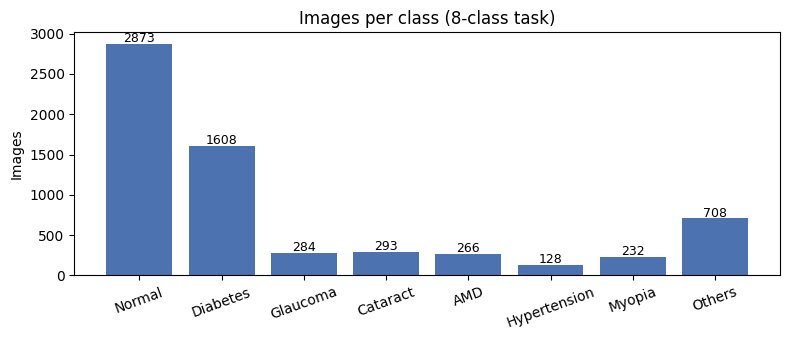

In [2]:
df = pd.read_csv(os.path.join(DATA_ROOT, "full_df.csv"))
df["diagnosis"] = df["labels"].str.strip("[]'\" ")
assert df["diagnosis"].isin(CLASSES).all(), "Unexpected label value found"
df["y"] = df["diagnosis"].map({c: i for i, c in enumerate(CLASSES)})

missing = (~df["filename"].apply(lambda f: os.path.isfile(os.path.join(IMG_DIR, f)))).sum()
print("Rows:", len(df), "| Unique patients:", df["ID"].nunique(), "| Missing image files:", missing)
print()
counts = df["diagnosis"].value_counts().reindex(CLASSES)
print(pd.DataFrame({"class": [CLASS_NAMES[c] for c in CLASSES], "images": counts.values,
                    "percent": (100 * counts / len(df)).round(1).values}, index=CLASSES))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar([CLASS_NAMES[c] for c in CLASSES], counts.values, color="#4C72B0")
for i, v in enumerate(counts.values):
    ax.text(i, v + 20, str(v), ha="center", fontsize=9)
ax.set_title("Images per class (8-class task)")
ax.set_ylabel("Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIGS, "stage9_class_distribution.png"), dpi=150)
plt.show()


## 3. Patient-level train / validation / test split (no leakage)

Many patients have two images (left + right eye). If one eye were in training and the other in testing, the model could "recognise the patient" instead of the disease. So we split by **patient ID** using `StratifiedGroupKFold` (20 folds → 3 folds test ≈ 15%, 3 folds validation ≈ 15%, 14 folds train ≈ 70%), which also keeps the class mix similar in every split.

In [3]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
df["fold"] = -1
for k, (_, idx) in enumerate(sgkf.split(df, df["y"], groups=df["ID"])):
    df.loc[df.index[idx], "fold"] = k
df["split"] = np.where(df["fold"] < 3, "test", np.where(df["fold"] < 6, "val", "train"))

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

# Leakage check: no patient may appear in two splits
ids = {s: set(d["ID"]) for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
overlap = len(ids["train"] & ids["val"]) + len(ids["train"] & ids["test"]) + len(ids["val"] & ids["test"])
print("Patients shared between splits:", overlap)
assert overlap == 0

summary = pd.DataFrame({s: d["diagnosis"].value_counts().reindex(CLASSES).fillna(0).astype(int)
                        for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]})
summary.index = [CLASS_NAMES[c] for c in CLASSES]
summary.loc["TOTAL images"] = summary.sum()
summary.loc["patients"] = [len(ids["train"]), len(ids["val"]), len(ids["test"])]
print(summary)

df[["ID", "filename", "diagnosis", "split"]].to_csv(os.path.join(OUT_DATA, "stage9_multiclass_split.csv"), index=False)


Patients shared between splits: 0
              train  val  test
Normal         2009  432   432
Diabetes       1125  242   241
Glaucoma        200   42    42
Cataract        204   45    44
AMD             186   40    40
Hypertension     90   20    18
Myopia          162   34    36
Others          496  105   107
TOTAL images   4472  960   960
patients       2349  505   504


## 4. Clinical model (age + sex) — preprocessing, feature selection, classification

**Feature selection (leakage review):** of the 19 columns, only `Patient Age` and `Patient Sex` are legitimate predictors.
`ID`, `filename`, `filepath`, `Left/Right-Fundus` are identifiers; `Left/Right-Diagnostic Keywords`, `N…O`, `labels`, `target` describe the diagnosis itself and would leak it.

**Preprocessing:** ages below 5 (28 rows — almost certainly data-entry errors in an adult fundus dataset) are treated as missing and filled with the *training* median; age is standardised with a scaler fitted on the training set only; sex is encoded Male=1 / Female=0.

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)

def clinical_features(d, age_median=None):
    age = d["Patient Age"].astype(float).where(d["Patient Age"] >= 5)
    return pd.DataFrame({"age": age, "sex_male": (d["Patient Sex"] == "Male").astype(float)}), age

Xtr, age_tr = clinical_features(train_df)
AGE_MEDIAN = float(age_tr.median())
print("Ages < 5 treated as missing (train/val/test):",
      int(age_tr.isna().sum()), int((val_df["Patient Age"] < 5).sum()), int((test_df["Patient Age"] < 5).sum()))
Xtr["age"] = Xtr["age"].fillna(AGE_MEDIAN)
Xva, _ = clinical_features(val_df); Xva["age"] = Xva["age"].fillna(AGE_MEDIAN)
Xte, _ = clinical_features(test_df); Xte["age"] = Xte["age"].fillna(AGE_MEDIAN)

scaler = StandardScaler().fit(Xtr[["age"]])
for X in (Xtr, Xva, Xte):
    X["age"] = scaler.transform(X[["age"]])
ytr, yva, yte = train_df["y"].values, val_df["y"].values, test_df["y"].values

def metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0)}

clinical_models = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=5,
                                                       class_weight="balanced", random_state=SEED, n_jobs=-1),
}
results = []
clinical_preds = {}
for name, m in clinical_models.items():
    m.fit(Xtr, ytr)
    p = m.predict(Xte)
    clinical_preds[name] = p
    r = {"model": "Clinical: " + name, **metrics(yte, p)}
    results.append(r)
print(pd.DataFrame(results).set_index("model").round(3))


Ages < 5 treated as missing (train/val/test): 21 2 5


                                          accuracy  precision_macro  \
model                                                                 
Clinical: Majority-class baseline            0.450            0.056   
Clinical: Logistic Regression (balanced)     0.078            0.092   
Clinical: Random Forest (balanced)           0.103            0.168   

                                          recall_macro  f1_macro  f1_weighted  
model                                                                          
Clinical: Majority-class baseline                0.125     0.078        0.279  
Clinical: Logistic Regression (balanced)         0.205     0.072        0.059  
Clinical: Random Forest (balanced)               0.190     0.106        0.113  


In [5]:
best_clin = max([r for r in results if "baseline" not in r["model"]], key=lambda r: r["f1_macro"])
best_clin_name = best_clin["model"].replace("Clinical: ", "")
print("Best clinical model (test macro-F1):", best_clin_name)
print()
print(classification_report(yte, clinical_preds[best_clin_name], target_names=[CLASS_NAMES[c] for c in CLASSES],
                            zero_division=0))


Best clinical model (test macro-F1): Random Forest (balanced)

              precision    recall  f1-score   support

      Normal       0.50      0.05      0.10       432
    Diabetes       0.31      0.11      0.16       241
    Glaucoma       0.05      0.10      0.06        42
    Cataract       0.12      0.27      0.17        44
         AMD       0.06      0.23      0.09        40
Hypertension       0.02      0.33      0.03        18
      Myopia       0.11      0.39      0.17        36
      Others       0.19      0.04      0.06       107

    accuracy                           0.10       960
   macro avg       0.17      0.19      0.11       960
weighted avg       0.34      0.10      0.11       960



## 5. Image model — MobileNetV2 (8 classes)

Same recipe that worked in Stage 8: ImageNet-pretrained MobileNetV2, early blocks frozen, **blocks 14-18 fine-tuned**, new 8-way classifier head.

Class imbalance (Normal is 22x bigger than Hypertension) is handled with a **class-weighted cross-entropy loss**. The checkpoint with the best **validation macro-F1** is kept (early stopping); the test set is used once, at the end.

In [6]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import models, transforms
from torchvision.models import MobileNet_V2_Weights

IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class FundusDS(Dataset):
    def __init__(self, d, tf):
        self.files, self.y, self.tf = d["filename"].tolist(), d["y"].tolist(), tf
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        img = Image.open(os.path.join(IMG_DIR, self.files[i])).convert("RGB")
        return self.tf(img), self.y[i]

BATCH = 32
# num_workers=0 keeps this working inside Jupyter on Windows
train_dl = DataLoader(FundusDS(train_df, train_tf), batch_size=BATCH, shuffle=True, num_workers=0)
val_dl = DataLoader(FundusDS(val_df, eval_tf), batch_size=64, shuffle=False, num_workers=0)
test_dl = DataLoader(FundusDS(test_df, eval_tf), batch_size=64, shuffle=False, num_workers=0)

UNFREEZE_FROM = 14
cnn = models.mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V1)
for i, block in enumerate(cnn.features):
    for p in block.parameters():
        p.requires_grad = i >= UNFREEZE_FROM
cnn.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(cnn.last_channel, len(CLASSES)))
cnn = cnn.to(device)

class_counts = np.bincount(ytr, minlength=len(CLASSES))
class_w = torch.tensor(len(ytr) / (len(CLASSES) * class_counts), dtype=torch.float32).to(device)
print("Class weights:", dict(zip(CLASSES, class_w.cpu().numpy().round(2))))
criterion = nn.CrossEntropyLoss(weight=class_w)
optimizer = torch.optim.AdamW([
    {"params": [p for p in cnn.features.parameters() if p.requires_grad], "lr": 1e-4},
    {"params": cnn.classifier.parameters(), "lr": 1e-3},
], weight_decay=1e-4)
print("Trainable parameters:", sum(p.numel() for p in cnn.parameters() if p.requires_grad))


Class weights: {'N': np.float32(0.28), 'D': np.float32(0.5), 'G': np.float32(2.8), 'C': np.float32(2.74), 'A': np.float32(3.01), 'H': np.float32(6.21), 'M': np.float32(3.45), 'O': np.float32(1.13)}
Trainable parameters: 1691592


Epoch  1 | train loss 1.5110 | val acc 0.427 | val macro-F1 0.393  <- best, saved | 181s


Epoch  2 | train loss 1.1164 | val acc 0.452 | val macro-F1 0.432  <- best, saved | 175s


Epoch  3 | train loss 0.9964 | val acc 0.376 | val macro-F1 0.414 | 174s


Epoch  4 | train loss 0.8749 | val acc 0.364 | val macro-F1 0.411 | 173s


Epoch  5 | train loss 0.7790 | val acc 0.460 | val macro-F1 0.456  <- best, saved | 174s


...

Epoch  9 | train loss 0.4807 | val acc 0.485 | val macro-F1 0.470 | 173s


Epoch 10 | train loss 0.4325 | val acc 0.524 | val macro-F1 0.485 | 176s


Epoch 11 | train loss 0.4003 | val acc 0.495 | val macro-F1 0.476 | 177s


Epoch 12 | train loss 0.3653 | val acc 0.497 | val macro-F1 0.485 | 178s


Early stopping (no val improvement for 5 epochs)


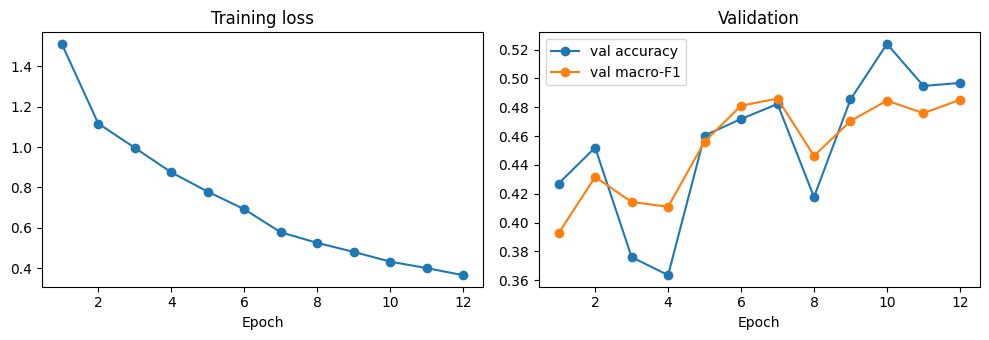

In [7]:
def predict(model, dl):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for x, y in dl:
            probs.append(torch.softmax(model(x.to(device)), 1).cpu())
            ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

EPOCHS = int(os.environ.get("MC_EPOCHS", 20))
PATIENCE = 5
CKPT = os.path.join(OUT_MODELS, "stage9_multiclass_mobilenetv2.pt")
history, best_f1, bad_epochs = [], -1, 0
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    cnn.train()
    # keep frozen BatchNorm layers in eval mode so their ImageNet statistics are not changed
    for i, block in enumerate(cnn.features):
        if i < UNFREEZE_FROM:
            block.eval()
    total, n = 0.0, 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(cnn(x), y)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(y); n += len(y)
    vp, vy = predict(cnn, val_dl)
    v_f1 = f1_score(vy, vp.argmax(1), average="macro")
    v_acc = accuracy_score(vy, vp.argmax(1))
    scheduler.step(v_f1)
    history.append({"epoch": epoch, "train_loss": total / n, "val_acc": v_acc, "val_f1_macro": v_f1})
    improved = v_f1 > best_f1
    if improved:
        best_f1, bad_epochs = v_f1, 0
        torch.save(cnn.state_dict(), CKPT)
    else:
        bad_epochs += 1
    print(f"Epoch {epoch:2d} | train loss {total/n:.4f} | val acc {v_acc:.3f} | val macro-F1 {v_f1:.3f}"
          f"{'  <- best, saved' if improved else ''} | {time.time()-t0:.0f}s", flush=True)
    if bad_epochs >= PATIENCE:
        print("Early stopping (no val improvement for", PATIENCE, "epochs)")
        break

hist = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist["epoch"], hist["train_loss"], marker="o"); ax[0].set_title("Training loss"); ax[0].set_xlabel("Epoch")
ax[1].plot(hist["epoch"], hist["val_acc"], marker="o", label="val accuracy")
ax[1].plot(hist["epoch"], hist["val_f1_macro"], marker="o", label="val macro-F1")
ax[1].set_title("Validation"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIGS, "stage9_cnn_training_curves.png"), dpi=150)
plt.show()


## 6. Test-set evaluation (used once)

              precision    recall  f1-score   support

      Normal       0.66      0.53      0.59       432
    Diabetes       0.51      0.38      0.44       241
    Glaucoma       0.23      0.36      0.28        42
    Cataract       0.61      0.82      0.70        44
         AMD       0.33      0.70      0.45        40
Hypertension       0.13      0.39      0.20        18
      Myopia       0.86      0.89      0.88        36
      Others       0.29      0.36      0.33       107

    accuracy                           0.50       960
   macro avg       0.45      0.55      0.48       960
weighted avg       0.54      0.50      0.51       960



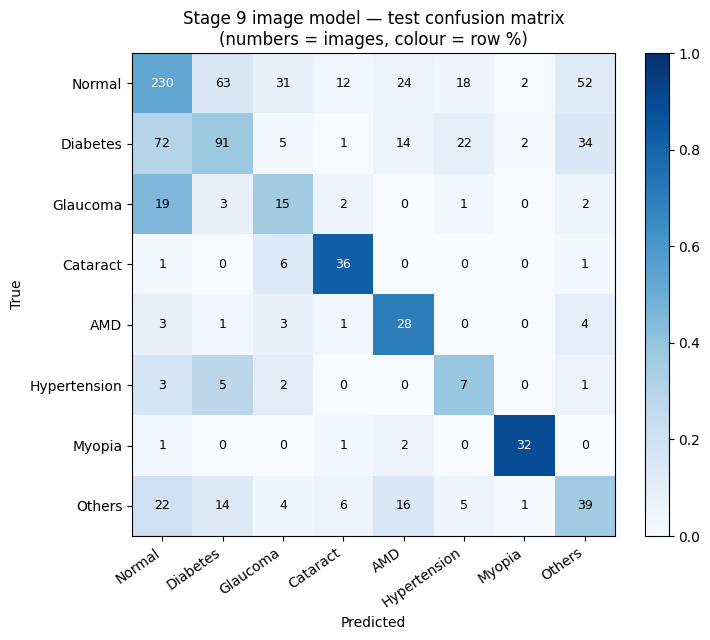

In [8]:
cnn.load_state_dict(torch.load(CKPT, map_location=device))
tp, ty = predict(cnn, test_dl)
cnn_pred = tp.argmax(1)
results.append({"model": "Image: MobileNetV2 (fine-tuned)", **metrics(ty, cnn_pred)})

print(classification_report(ty, cnn_pred, target_names=[CLASS_NAMES[c] for c in CLASSES], zero_division=0))

cm = confusion_matrix(ty, cnn_pred, labels=range(len(CLASSES)))
cm_norm = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
names = [CLASS_NAMES[c] for c in CLASSES]
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(names, rotation=35, ha="right")
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(names)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=9)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Stage 9 image model — test confusion matrix\n(numbers = images, colour = row %)")
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIGS, "stage9_cnn_confusion_matrix.png"), dpi=150)
plt.show()


## 7. Comparison and saved outputs

In [9]:
comp = pd.DataFrame(results).set_index("model")
print(comp.round(3))
comp.to_csv(os.path.join(OUT_DATA, "stage9_multiclass_comparison.csv"))

per_class = pd.DataFrame({
    "class": names,
    "test_images": np.bincount(ty, minlength=len(CLASSES)),
    "train_images": class_counts,
    "cnn_recall": recall_score(ty, cnn_pred, average=None, labels=range(len(CLASSES)), zero_division=0),
    "cnn_precision": precision_score(ty, cnn_pred, average=None, labels=range(len(CLASSES)), zero_division=0),
    "cnn_f1": f1_score(ty, cnn_pred, average=None, labels=range(len(CLASSES)), zero_division=0),
}).round(3)
print()
print(per_class.to_string(index=False))
per_class.to_csv(os.path.join(OUT_DATA, "stage9_cnn_per_class.csv"), index=False)

config = {"classes": CLASSES, "class_names": CLASS_NAMES, "architecture": "mobilenet_v2",
          "unfreeze_from_block": UNFREEZE_FROM, "checkpoint": "Code/models/stage9_multiclass_mobilenetv2.pt",
          "best_val_f1_macro": best_f1, "epochs_run": len(history), "device_used": str(device),
          "test_metrics": {k: float(v) for k, v in comp.loc["Image: MobileNetV2 (fine-tuned)"].items()}}
with open(os.path.join(OUT_DATA, "stage9_multiclass_config.json"), "w") as f:
    json.dump(config, f, indent=2)
print("\nSaved: Data/stage9_multiclass_comparison.csv, Data/stage9_cnn_per_class.csv, "
      "Data/stage9_multiclass_config.json, Code/models/stage9_multiclass_mobilenetv2.pt")


                                          accuracy  precision_macro  \
model                                                                 
Clinical: Majority-class baseline            0.450            0.056   
Clinical: Logistic Regression (balanced)     0.078            0.092   
Clinical: Random Forest (balanced)           0.103            0.168   
Image: MobileNetV2 (fine-tuned)              0.498            0.454   

                                          recall_macro  f1_macro  f1_weighted  
model                                                                          
Clinical: Majority-class baseline                0.125     0.078        0.279  
Clinical: Logistic Regression (balanced)         0.205     0.072        0.059  
Clinical: Random Forest (balanced)               0.190     0.106        0.113  
Image: MobileNetV2 (fine-tuned)                  0.553     0.481        0.509  

       class  test_images  train_images  cnn_recall  cnn_precision  cnn_f1
      Normal     